In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("../src")

import pandas as pd
from features import add_target, add_distance_angle

In [2]:
df = pd.read_pickle("../data/raw/shots.pkl")
df = add_target(df)
df = add_distance_angle(df)

print(f"Taux de buts : {df['is_goal'].mean():.1%}")
df[["x", "y", "distance", "angle", "is_goal"]].head()

Taux de buts : 11.3%


,x,y,distance,angle,is_goal
0,91.0,51.0,31.016125,13.779441,0
1,115.0,39.0,5.099020,75.963757,0
2,106.0,31.0,16.643317,23.225080,0
3,92.0,29.0,30.083218,14.142347,0
4,109.0,46.0,12.529964,31.968843,0


In [3]:
df[df["shot_type"] == "Penalty"][["x", "y", "distance", "angle"]].head()

,x,y,distance,angle
77,109.0,41.0,11.045361,39.699073
82,109.0,41.0,11.045361,39.699073
155,109.0,41.0,11.045361,39.699073
305,108.0,40.0,12.000000,36.869898
324,109.0,41.0,11.045361,39.699073


In [4]:
df["distance_bin"] = pd.cut(df["distance"], bins=[0, 6, 12, 18, 24, 30, 40, 120])
df.groupby("distance_bin")["is_goal"].agg(["mean", "count"])

,mean,count
distance_bin,,
"(0, 6]",0.404494,178
"(6, 12]",0.232962,1438
"(12, 18]",0.110375,1359
"(18, 24]",0.045566,1229
"(24, 30]",0.034862,1090
"(30, 40]",0.014085,497
"(40, 120]",0.026316,38


In [5]:
df[df["shot_type"] == "Penalty"].groupby("competition")[["x", "y"]].mean()

,x,y
competition,,
FIFA World Cup 2018,108.647059,40.647059
FIFA World Cup 2022,108.053125,40.053125
UEFA Euro 2020,107.989091,40.016364
UEFA Euro 2024,108.088889,40.083333


In [6]:
df["angle_bin"] = pd.cut(df["angle"], bins=[0, 10, 20, 30, 45, 60, 90, 180])
df.groupby("angle_bin")["is_goal"].agg(["mean", "count"])

,mean,count
angle_bin,,
"(0, 10]",0.028369,141
"(10, 20]",0.035490,2705
"(20, 30]",0.100159,1258
"(30, 45]",0.255121,1074
"(45, 60]",0.168646,421
"(60, 90]",0.354497,189
"(90, 180]",0.552632,38


In [7]:
from features import build_features

raw = pd.read_pickle("../data/raw/shots.pkl")
df = build_features(raw)
print(f"{len(raw)} tirs bruts -> {len(df)} tirs après retrait des penalties")

5829 tirs bruts -> 5606 tirs après retrait des penalties


In [8]:
for col in ["is_header", "under_pressure", "shot_first_time", "shot_one_on_one", "shot_open_goal"]:
    print(df.groupby(col)["is_goal"].agg(["mean", "count"]), "\n")

               mean  count
is_header                 
0          0.087486   4595
1          0.103858   1011 

                    mean  count
under_pressure                 
0               0.095928   4347
1               0.071485   1259 

                     mean  count
shot_first_time                 
0                0.074619   4007
1                0.130081   1599 

                     mean  count
shot_one_on_one                 
0                0.084062   5377
1                0.240175    229 

                    mean  count
shot_open_goal                 
0               0.084654   5552
1               0.685185     54 



In [9]:
df.groupby("play_pattern")["is_goal"].agg(["mean", "count"]).sort_values("mean", ascending=False)

,mean,count
play_pattern,,
Other,0.200000,15
From Keeper,0.155340,103
From Counter,0.153509,228
From Throw In,0.093504,1016
Regular Play,0.090675,1941
From Goal Kick,0.090129,233
From Free Kick,0.081232,1071
From Corner,0.074946,934
From Kick Off,0.061538,65


In [10]:
df["distance_bin"] = pd.cut(df["distance"], bins=[0, 6, 12, 18, 24, 30, 40, 120])
df.groupby(["distance_bin", "is_header"])["is_goal"].mean().unstack()

is_header,0,1
distance_bin,,
"(0, 6]",0.494624,0.305882
"(6, 12]",0.232775,0.103152
"(12, 18]",0.114667,0.032710
"(18, 24]",0.046091,0.000000
"(24, 30]",0.034862,NaN
"(30, 40]",0.014085,NaN
"(40, 120]",0.026316,NaN


In [11]:
frame = df["shot_freeze_frame"].iloc[0]
print(f"{len(frame)} joueurs visibles")
frame[0]

12 joueurs visibles


{'location': [100.0, 50.0],
 'player': {'id': 5552, 'name': 'Marcelo Vieira da Silva Júnior'},
 'position': {'id': 6, 'name': 'Left Back'},
 'teammate': False}

In [12]:
for player in frame:
    if player["teammate"] == False:
        print(player["position"]["name"], player["location"])

Left Back [100.0, 50.0]
Center Midfield [81.0, 42.0]
Right Midfield [88.0, 36.0]
Left Midfield [88.0, 43.0]
Goalkeeper [118.0, 41.0]
Right Back [95.0, 33.0]
Right Center Back [97.0, 37.0]
Left Center Back [96.0, 47.0]


In [13]:
import numpy as np

for player in frame:
    if player["teammate"] == False and player["position"]["name"] == "Goalkeeper":
        gk_x, gk_y = player["location"]
        gk_dist = np.hypot(120 - gk_x, 40 - gk_y)
        print(f"Gardien en ({gk_x}, {gk_y}), à {gk_dist:.2f} yards de son but")

Gardien en (118.0, 41.0), à 2.24 yards de son but


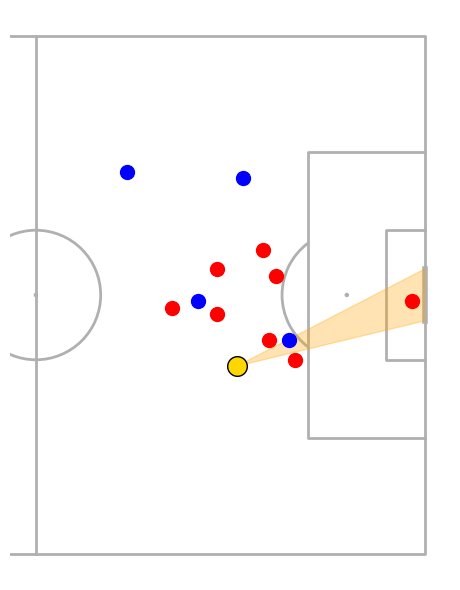

In [14]:
import matplotlib.pyplot as plt
from mplsoccer import Pitch

shooter = df["location"].iloc[0]

pitch = Pitch(pitch_type="statsbomb", half=True)
fig, ax = pitch.draw(figsize=(8, 6))

pitch.polygon([[shooter, (120, 36), (120, 44)]], ax=ax, color="orange", alpha=0.3)

for player in frame:
    x, y = player["location"]
    color = "blue" if player["teammate"] else "red"
    pitch.scatter(x, y, ax=ax, color=color, s=100)

pitch.scatter(shooter[0], shooter[1], ax=ax, color="gold", s=200, edgecolors="black")
plt.show()

In [15]:
def point_in_triangle(p, a, b, c):
    def side(p1, p2, p3):
        return (p1[0] - p3[0]) * (p2[1] - p3[1]) - (p2[0] - p3[0]) * (p1[1] - p3[1])

    d1 = side(p, a, b)
    d2 = side(p, b, c)
    d3 = side(p, c, a)
    has_neg = d1 < 0 or d2 < 0 or d3 < 0
    has_pos = d1 > 0 or d2 > 0 or d3 > 0
    return not (has_neg and has_pos)

In [16]:
for player in frame:
    if player["teammate"] == False:
        inside = point_in_triangle(player["location"], shooter, (120, 36), (120, 44))
        print(player["position"]["name"], inside)

Left Back False
Center Midfield False
Right Midfield False
Left Midfield False
Goalkeeper True
Right Back False
Right Center Back False
Left Center Back False


In [17]:
from features import freeze_frame_stats

freeze_frame_stats(frame, shooter)

{'n_def_in_cone': 0,
 'n_def_close': 0,
 'gk_dist_to_goal': np.float64(2.23606797749979)}

In [18]:
df = build_features(raw)
df[["n_def_in_cone", "n_def_close", "gk_dist_to_goal"]].describe()

,n_def_in_cone,n_def_close,gk_dist_to_goal
count,5606.000000,5606.000000,5605.000000
mean,0.805209,0.883696,3.098254
std,0.973813,0.900210,2.372440
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,1.910497
50%,1.000000,1.000000,2.773085
75%,1.000000,1.000000,3.758989
max,7.000000,5.000000,64.764960


In [19]:
import inspect
print(inspect.getsource(build_features))

def build_features(df):
    df = add_target(df)
    df = remove_penalties(df)
    df = add_distance_angle(df)
    df = clean_boolean_flags(df)
    df = add_body_part(df)
    df = add_freeze_frame_features(df)
    return df



In [20]:
df.groupby("n_def_in_cone")["is_goal"].agg(["mean", "count"])

,mean,count
n_def_in_cone,,
0.0,0.127384,2622
1.0,0.066871,1959
2.0,0.045249,663
3.0,0.035573,253
4.0,0.012500,80
5.0,0.040000,25
6.0,0.333333,3
7.0,0.000000,1
